In [33]:
import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader
import torch.nn as nn
import matplotlib.pyplot as plt
from scipy.integrate import odeint
from numpy.polynomial.legendre import legvander

In [34]:
SEED = 42                           # SEED wird dafür gebraucht, dass sich nicht bei jedem Lauf die Anfangsbedingungen, die Trainings-, Validierungsdaten und die Anfänglichen Gewichte des Autoencoders verändern
                                    # Damit wird ein Autoencoder mit verschiedenen Aktivierungsfunktionen vergleichbar
np.random.seed(SEED)
torch.manual_seed(SEED)             # PyTorch SEED. Modellgewichte beginnen bei erneutem Durchlauf mit der gleichen zufälligen Initialisierung

rng = np.random.default_rng(SEED)

# Anzahl der Trajektorien
N_TRAIN_TRAJECTORIES = 100          # 100 * 249 = Anzahl Datensätze. 249 da es beim letzten Zustand in der Trajectory keinen nachfolgenden Zustand mehr gibt
N_VAL_TRAJECTORIES = 20


BATCH_SIZE = 1024                   # Pro optimierungsschritt werden höchsten 1024 Übergänge verarbeitet
EPOCHS = 700                        # Anzahl der Epochen, die trainiert werden. 1 Epoche = Modell hat alle Trainingsdateien gesehen
LEARNING_RATE = 3e-4                # Schrittweite des Adam Optimierers
PRINT_FREQUENCY = 10
HORIZON = 30


NOISE_STRENGTH = 0.025

Definition des Lorenzsystems

In [35]:
def lorenz(state, t, sigma=10., rho=28., beta=8/3):

    x, y, z = state
    dx = sigma * (y - x)
    dy = x * (rho - z) - y
    dz = x * y - beta * z

    return [dx, dy, dz]

Räumliche Basis

In [36]:
t = np.arange(0.0, 5.0, 0.02)       # Erzeugen eines Zeitvektors. t = 0.0 bis t = 5.0 Schrittweite = 0.02. Ergibt 250 Zeitpunkte. t + 1 bedeutet nächte Arrayindex
grid = np.linspace(-1, 1, 128)      # Erzeugt 128 gleichmäßig verteilte Punkte auf dem Intervall [-1, 1]
U = legvander(grid, 5)              # Erzeugt Vandermonde-Matrix für Legendre-Polynome. Für jeden Punkt aus grid werden die ersten 6 Legendre-Polynome ausgewertet.

Erstellen des künstlichen 128 dimensionalen Datensatz

In [37]:
def create_lorenz_dataset(number_of_trajectories):
    ic_means = np.array([0.0, 0.0, 25.0])                                                                       # Mittelpunkte der Verteilung der Anfangszustände
    ic_widths = 2.0 * np.array([36.0, 48.0, 41.0])                                                              # Intervallbreiten
    initial_conditions = (ic_widths * (np.random.rand(number_of_trajectories, 3) - 0.5)) + ic_means             # Erstellen der zufälligen Anfangszustände

    Z_raw = np.stack([odeint(lorenz, z0, t) for z0 in initial_conditions])                                      # Für jede Anfangsbedingung z0 wird das Lorenz System über die 250 Zeitpunkte integriert.

    Z_scaled = Z_raw / 40.0                                                                                     # Skalierung

    Z_scaled = Z_scaled.astype(np.float32)                                                                      # Wandelt in Gleitkommazahl um (Für PyTorch)

    modes = np.concatenate([                                                                                    # Erstellen der Gleichung aus dem Paper: z1(t), z2(t), z3(t), z1(t)^3, z2(t)^3, z3(t)^3
        Z_scaled,
        Z_scaled**3
    ], axis=2)

    X = modes @ U.T                                                                                             # modes wird mit transponierter Legendre-Matrix multipliziert

    return Z_raw, Z_scaled, X.astype(np.float32)

Trainings, Validierrungsdaten erzeugen

In [38]:
# Daten werden nach Trajektorien getrennt
Z_train_raw, Z_train, X_train = create_lorenz_dataset(N_TRAIN_TRAJECTORIES)
Z_val_raw, Z_val, X_val = create_lorenz_dataset(N_VAL_TRAJECTORIES)


Erzeugung der t- und t + 1-Paare

In [39]:
def make_pairs(X, horizon):
    x_t = X[:, :-horizon, :].reshape(-1,128)

    x_future = np.stack([X[:, k:X.shape[1] - horizon + k, :]                                                    # Zu jedem Startzustand werden die passenden Folgezustände zusammengestellt.
                         for k in range(1, horizon + 1)],
                        axis=2
    ).reshape(-1, horizon, 128)

    return x_t, x_future

# X(t): alle Zeitpunkte außer dem letzten
X_train_t = X_train[:, :-1, :].reshape(-1, 128)
X_val_t = X_val[:, :-1, :].reshape(-1, 128)

# X(t+1): alle Zeitpunkte außer dem ersten
X_train_tp1 = X_train[:, 1:, :].reshape(-1, 128)
X_val_tp1 = X_val[:, 1:, :].reshape(-1, 128)

# Erstellt PyTorch tensor und ascontiguousarray sorgt dafür, dass die Daten zusammenhängend im Speicher liegen
X_train_t_tensor = torch.from_numpy(np.ascontiguousarray(X_train_t))
X_train_tp1_tensor = torch.from_numpy(np.ascontiguousarray(X_train_tp1))
X_val_t_tensor = torch.from_numpy(np.ascontiguousarray(X_val_t))
X_val_tp1_tensor = torch.from_numpy(np.ascontiguousarray(X_val_tp1))

Daten für Training mit PyTorch vorbereiten

In [40]:
train_dataset = TensorDataset(                              # TensorDataset verbindet beide Tensoren, sodass ein aktueller Zustand X(t) und der dazugehörige Folgezustand X(t+1) immer gemeinsam als Trainingsbeispiel genommen
                                                            # werden
    X_train_t_tensor,
    X_train_tp1_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,                                  # BATCH SIZE verarbeitet höchstens BATCH_SIZE Übergänge gleichzeitig. Ein Übergang ist: X(t) -> X(t+1)
    shuffle=True,
    drop_last=False
)

Erstellen des Autoencoders

In [41]:
class PredictiveAutoencoder(nn.Module):

    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(128, 64),
            nn.SiLU(),

            nn.Linear(64, 32),
            nn.SiLU(),

            nn.Linear(32, 16),
            nn.SiLU(),

            nn.Linear(16, 3)
        )

        # Soll zeitliche Bewegung im dreidimensionalen latenten Raum lernen
        # Bekommt aktuellen Latenten Zustand und berechnet wie sich dieser bis zum nächsten Zeitpunkt verändern soll
        self.latent_dynamics = nn.Sequential(
            nn.Linear(3, 16),
            nn.SiLU(),
            nn.Linear(16, 3)
        )

        self.decoder = nn.Sequential(
            nn.Linear(3, 16),
            nn.SiLU(),

            nn.Linear(16, 32),
            nn.SiLU(),

            nn.Linear(32, 64),
            nn.SiLU(),

            nn.Linear(64, 128)
        )
    # Beschreibt den vollständigen Vorwärtsdurchlauf des Modells während des Trainings und der Validierung
    def forward(self, x_t, x_tp1, teacher_forcing=False):                   # x_t = aktueller Zustand, x_tp1 = echter nächste Zustand

        z_t = self.encoder(x_t)                                             # Komprimiert 128d Zustand auf drei latente Werte. X(t) durch encoder
        z_tp1 = self.encoder(x_tp1)                                         # Tatsächlich vorhandener nächster Zustand ebenfalls auf drei Dimensionen komprimiert. Echtes X(t+1) durch Encoder
        x_t_hat = self.decoder(z_t)                                         # Rekonstruktion von X(t). z(t) wird durch den decoder geschickt

        is_sequence = x_tp1.ndim == 3
        steps = x_tp1.shape[1] if is_sequence else 1

        z_current = z_t
        predictions = []

        for step in range(steps):
            z_current = z_current + self.latent_dynamics(z_current)
            predictions.append(z_current)

            if teacher_forcing and is_sequence and step < steps - 1:
                z_current = z_tp1[:, step, :]


        if is_sequence:
            z_tp1_hat = torch.stack(predictions, dim=1)
        else:
            z_tp1_hat = predictions[0]

        x_tp1_hat = self.decoder(z_tp1_hat)

        return x_t_hat, z_tp1, z_tp1_hat, x_tp1_hat

Trainieren des Autoencoders

In [42]:
model = PredictiveAutoencoder()                                             # Erstellen des Models

trainable_parameters = sum(param.numel() for param in model.parameters() if param.requires_grad)
print(trainable_parameters)


criterion = nn.MSELoss()                                                    # Mean Squared Error Fehlerfunktion. Berechnet durchschnittliche quadratische Abweichung zwischen Vorhersage und Ziel. Durch quadreieren werden
                                                                            # größere Abweichungen stärker bestraft

optimizer = torch.optim.Adam(                                               # Adam optimierungsalgorithmus
    model.parameters(),
    lr=LEARNING_RATE
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)   # Dynamische Learningrate (cosinusförmig)

train_loss_history = []
val_loss_history = []

val_reconstruction_history = []
val_latent_history = []
val_prediction_history = []

for epoch in range(EPOCHS):

    model.train()                                                           # Trainingsmodus
    total_train_loss = 0.0
    total_train_samples = 0

    for x_t, x_tp1 in train_loader:                                         # Lädt einen Batch zusammengehöriger X(t)- und X(t+1)-Zustände
        optimizer.zero_grad()                                               # Lösche Gradienten aus dem vorherigen Batch

        if NOISE_STRENGTH > 0:                                              # Hinzufügen von Noise
            noise = NOISE_STRENGTH * torch.randn_like(x_t)
            x_t_noisy = x_t + noise
        else:
            x_t_noisy = x_t


        x_t_hat, z_tp1, z_tp1_hat, x_tp1_hat = model(x_t_noisy, x_tp1)      # Vorwärtsdurchlauf

        reconstruction_loss = criterion(x_t_hat, x_t)                       # Berechnet den Rekonstruktionsfehler. Sorgt dafür, dass der dreidimensionale Latentraum genügend Informationen zur Rekonstruktion erhält

        latent_loss = criterion(z_tp1_hat, z_tp1)                           # Berechnet den Latentenfehler. Dadurch soll die Vorhersage mit dem Encoder-Ergebnis des echten nächsten Zustand übereinstimmen

        prediction_loss = criterion(x_tp1_hat, x_tp1)                       # Vorhersagefehler. Wichtigster Fehler für die Ein-Schritt-Vorhersage.


        loss = (reconstruction_loss + 0.1 * latent_loss + prediction_loss)  # Gesamtfehler.
                                                                            # Ein zu stark gewichteter Latent loss könnte die Optimierung dominieren und Rekonstruktion der physischen Vorhersage verschlechtern.

        loss.backward()                                                     # Berechnet mit Backpropagation die Gradienten aller Modellparameter
        optimizer.step()                                                    # Aktualisiert Encoder, Dynamiknetz und Decoder

        batch_size = x_t.shape[0]                                           # Ermittelt die tatsächliche Größe des aktuellen Batches

        total_train_loss += loss.item() * batch_size                        # Multipliziert den mittleren Batchfehler mit der Zahl der Beispiele

        total_train_samples += batch_size                                   # Zählt die verarbeiteten Beispiele.

    train_loss = total_train_loss / total_train_samples                     # Mittlerer Gesamtfehler über alle Trainingsübergänge der gesamten Epoche
    train_loss_history.append(train_loss)                                   # Speichert wert für späteren Plot.

    model.eval()                                                            # Modell wird in Auswertungsmodus gesetzt

    with torch.inference_mode():                                                                    # Deaktiviert Gradientenberechnung -> Validierung wird schneller
        x_t_hat, z_tp1, z_tp1_hat, x_tp1_hat = model(X_val_t_tensor, X_val_tp1_tensor)              # Verarbeitet Validierungsdatensatz auf einmal
        val_reconstruction_loss = criterion(x_t_hat, X_val_t_tensor)                                # Misst Rekonstruktion von X(t)
        val_latent_loss = criterion(z_tp1_hat, z_tp1)                                               # Misst Vorhersage von z(t+1)
        val_prediction_loss = criterion(x_tp1_hat, X_val_tp1_tensor)                                # Misst die Vorhersage von X(t+1)
        val_loss = (val_reconstruction_loss + 0.1 * val_latent_loss + val_prediction_loss)          # Gesamtfehler der Validierung. Berechnung ist identisch zum Trainingsfehler

    # Werte speichern für Graphen
    val_loss_history.append(val_loss.item())                                                        # Durch .append wird der fehler immer hinten an die Liste angefügt. Dies ermöglicht das plotten
    val_reconstruction_history.append(val_reconstruction_loss.item())
    val_latent_history.append(val_latent_loss.item())
    val_prediction_history.append(val_prediction_loss.item())

    scheduler.step()                                                            # Learningrate wird angepasst

    if epoch % PRINT_FREQUENCY == 0 or epoch == EPOCHS - 1:
        print(
            f"Epoch {epoch:4d} | "
            f"Training: {train_loss:.6e} | "
            f"Validierung: {val_loss.item():.6e} | "
            f"Rekonstruktion: "
            f"{val_reconstruction_loss.item():.6e} | "
            f"Latent t+1: "
            f"{val_latent_loss.item():.6e} | "
            f"Vorhersage X(t+1): "
            f"{val_prediction_loss.item():.6e}"
        )

22070
Epoch    0 | Training: 3.942117e-01 | Validierung: 3.598008e-01 | Rekonstruktion: 1.794116e-01 | Latent t+1: 3.161544e-02 | Vorhersage X(t+1): 1.772277e-01
Epoch   10 | Training: 8.410548e-02 | Validierung: 7.231294e-02 | Rekonstruktion: 3.566199e-02 | Latent t+1: 2.254063e-02 | Vorhersage X(t+1): 3.439689e-02
Epoch   20 | Training: 2.108016e-02 | Validierung: 2.031817e-02 | Rekonstruktion: 8.968990e-03 | Latent t+1: 2.332212e-02 | Vorhersage X(t+1): 9.016967e-03
Epoch   30 | Training: 1.598936e-02 | Validierung: 1.587094e-02 | Rekonstruktion: 7.473226e-03 | Latent t+1: 1.215205e-02 | Vorhersage X(t+1): 7.182506e-03
Epoch   40 | Training: 1.362958e-02 | Validierung: 1.345745e-02 | Rekonstruktion: 6.550780e-03 | Latent t+1: 7.725575e-03 | Vorhersage X(t+1): 6.134112e-03
Epoch   50 | Training: 1.194554e-02 | Validierung: 1.185020e-02 | Rekonstruktion: 5.828416e-03 | Latent t+1: 6.503646e-03 | Vorhersage X(t+1): 5.371420e-03
Epoch   60 | Training: 1.014479e-02 | Validierung: 9.97964

In [43]:
X_eval_start, X_eval_future = make_pairs(X_val, HORIZON)

device = next(model.parameters()).device

X_eval_start_tensor = torch.from_numpy(np.ascontiguousarray(X_eval_start)).to(device)
X_eval_future_tensor = torch.from_numpy(np.ascontiguousarray(X_eval_future)).to(device)

def compare_prediction_modes(model, x_t, x_future):
    model.eval()

    with torch.inference_mode():

        # Teacher Forcing:
        # Jeder Schritt startet mit dem echten vorherigen Zustand.
        _, _, _, prediction_teacher_forced = model(
            x_t,
            x_future,
            teacher_forcing=True
        )

        # Autoregressiv:
        # Eigene Vorhersage wird für den nächsten Schritt verwendet.
        _, _, _, prediction_autoregressive = model(
            x_t,
            x_future,
            teacher_forcing=False
        )

    # Fehler für jeden einzelnen Zukunftsschritt.
    mse_teacher_forced = ((prediction_teacher_forced - x_future) ** 2).mean(dim=(0, 2))

    mse_autoregressive = ((prediction_autoregressive - x_future) ** 2).mean(dim=(0, 2))

    print(mse_teacher_forced)
    print(mse_autoregressive)

    return prediction_teacher_forced, prediction_autoregressive, mse_teacher_forced, mse_autoregressive

(
    prediction_teacher_forced,
    prediction_autoregressive,
    mse_teacher_forced,
    mse_autoregressive
) = compare_prediction_modes(
    model,
    X_eval_start_tensor,
    X_eval_future_tensor
)

tensor([8.1954e-05, 4.1872e-05, 2.7034e-05, 1.0870e-05, 9.0425e-06, 5.9646e-06,
        5.3168e-06, 4.9676e-06, 4.6720e-06, 4.3897e-06, 4.1298e-06, 3.9522e-06,
        3.8057e-06, 3.6731e-06, 3.5750e-06, 3.5008e-06, 3.4389e-06, 3.3873e-06,
        3.3520e-06, 3.3301e-06, 3.3169e-06, 3.3087e-06, 3.3047e-06, 3.3033e-06,
        3.3030e-06, 3.3025e-06, 3.3029e-06, 3.3038e-06, 3.3043e-06, 3.3055e-06])
tensor([8.1954e-05, 1.9035e-04, 5.1221e-04, 2.5879e-04, 3.4995e-04, 3.0944e-04,
        2.7589e-04, 2.9948e-04, 3.3575e-04, 4.0770e-04, 4.6941e-04, 4.5854e-04,
        5.3555e-04, 6.7185e-04, 8.2896e-04, 1.0411e-03, 1.3322e-03, 1.7277e-03,
        2.2585e-03, 2.9610e-03, 3.8712e-03, 5.0120e-03, 6.3852e-03, 7.9760e-03,
        9.7590e-03, 1.1640e-02, 1.3362e-02, 1.4582e-02, 1.5120e-02, 1.5150e-02])


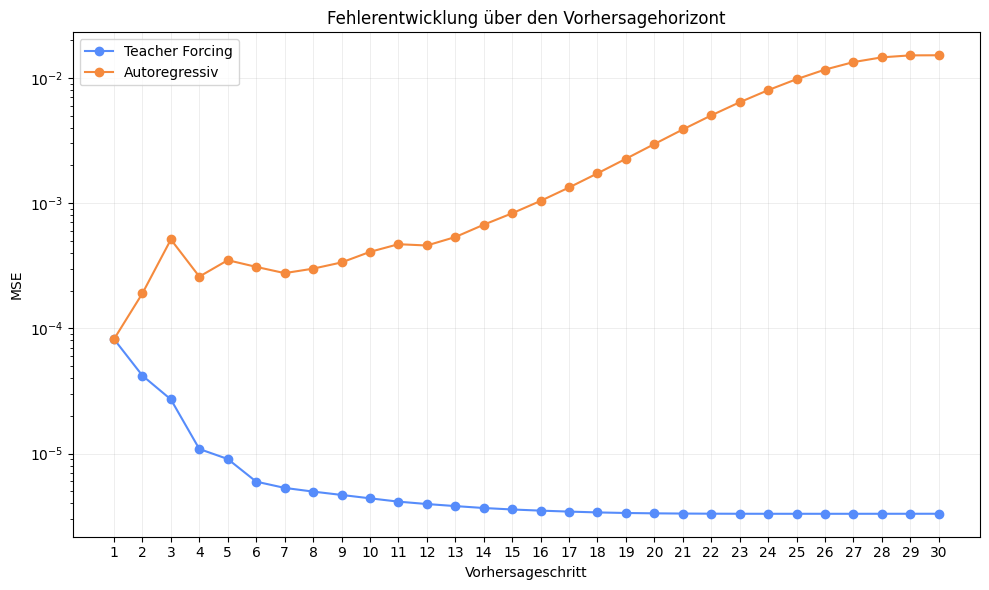

In [45]:
steps = np.arange(1, HORIZON + 1)

plt.figure(figsize=(10, 6))

plt.plot(
    steps,
    mse_teacher_forced.numpy(),
    marker="o",
    label="Teacher Forcing"
)

plt.plot(
    steps,
    mse_autoregressive.numpy(),
    marker="o",
    label="Autoregressiv"
)

plt.yscale("log")

plt.xlabel("Vorhersageschritt")
plt.ylabel("MSE")
plt.title(
    "Fehlerentwicklung über den Vorhersagehorizont"
)

plt.xticks(steps)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

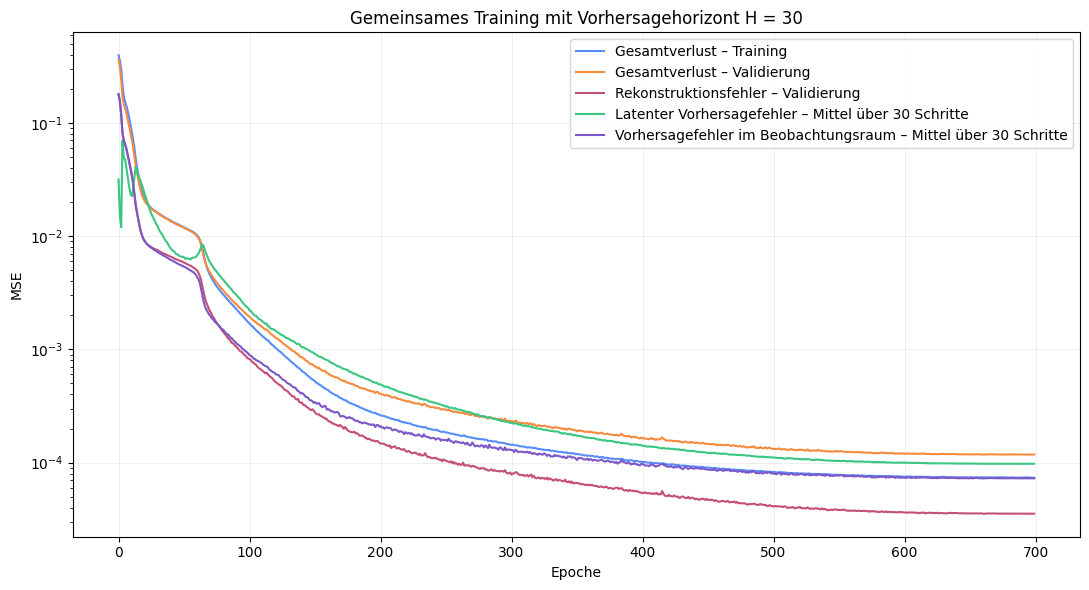

In [46]:
plt.figure(figsize=(11, 6))

plt.plot(train_loss_history, label="Gesamtverlust – Training")
plt.plot(val_loss_history, label="Gesamtverlust – Validierung")

plt.plot(
    val_reconstruction_history,
    label="Rekonstruktionsfehler – Validierung"
)

plt.plot(
    val_latent_history,
    label=f"Latenter Vorhersagefehler – Mittel über {HORIZON} Schritte"
)

plt.plot(
    val_prediction_history,
    label=f"Vorhersagefehler im Beobachtungsraum – Mittel über {HORIZON} Schritte"
)

plt.yscale("log")
plt.xlabel("Epoche")
plt.ylabel("MSE")
plt.title(f"Gemeinsames Training mit Vorhersagehorizont H = {HORIZON}")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()